# **Notebook 7: Solution V2 — Fine-Tuned RAG Evaluation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./intent_lora_best/` — Created by Notebook 6
- [ ] `./chroma_db/` — Created by Notebook 4
- [ ] `df_test.csv` — Created by Notebook 2
- [ ] `outputs.json` + `v1_metrics.csv` — From Notebooks 3/4/5
- [ ] GPU runtime enabled

**Files this notebook will CREATE:**
- [ ] `Comparative_Results_Full.csv` + `Comparative_Results_Summary.csv` _(Final deliverables)_

---

### **Task 4.3: Integrate Fine-Tuned Model with Retrieval**

#### **4.3.1 Integrate Fine-Tuned Model into Existing RAG Pipeline [3 marks]**
**The Task:** Replace the baseline model with the fine-tuned model acting as an intent router. Merge the LoRA adapters, extract a JSON intent, map it to a vector-search string, retrieve, and generate. Validate the integrated system.

**Hints & Tips:**
* `PeftModel.from_pretrained(base_model, "./intent_lora_best").merge_and_unload()` fuses the adapters for fast inference.
* Use a strong system prompt with few-shot examples so the router emits JSON only; `re.search(r'\{.*?\}', raw)` is a safety net for stray preamble.
* Map the intent (e.g. `track_order`) to an SOP header search string (e.g. `# Track Order`). Fall back to the raw query if JSON parsing fails.
* Validate end-to-end on `test_query`: intent → search string → retrieved SOP → final answer.

**Parameter Tuning:**
* `max_new_tokens=30` for the router (JSON is short — more tokens invite trailing explanation text).
* 4 few-shot examples is the sweet spot.

**Learner Inference:** Querying with the structured intent keyword instead of the noisy prompt retrieves the exact policy clause — the core of Hybrid RAG.

In [1]:
%pip install -q -U bitsandbytes peft accelerate langchain-huggingface langchain-chroma chromadb sentence-transformers rouge-score nltk
# Colab's torchao 0.10 is too old for the current peft and breaks PeftModel.from_pretrained; we don't need it
%pip uninstall -y -q torchao

import os, re, glob, json, time, shutil
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/hybrid_rag')
SEED = 42
torch.manual_seed(SEED)

with open('outputs.json') as f:
    outputs = json.load(f)
with open('router_config.json') as f:
    router_config = json.load(f)
with open('intent_sop_map.json') as f:
    intent_sop_map = json.load(f)
MODEL_ID = outputs['model_id']
GEN_KWARGS = outputs['gen_kwargs']
RAG_PROMPT = outputs['rag_config']['rag_prompt']
TOP_K = outputs['rag_config']['top_k']

df_test = pd.read_csv('df_test.csv', keep_default_na=False, na_values=[''])
df_test['reference_sop'] = df_test['intent'].map(lambda i: intent_sop_map[i]['sop_file'])
sop_text = {os.path.basename(f): open(f, encoding='utf-8').read() for f in glob.glob('corporate_policies/*.md')}

LOCAL_DB = '/tmp/chroma_db'
shutil.rmtree(LOCAL_DB, ignore_errors=True)
shutil.copytree('chroma_db', LOCAL_DB)
embeddings = HuggingFaceEmbeddings(model_name=outputs['rag_config']['embed_model'], encode_kwargs={'normalize_embeddings': True})
vector_db = Chroma(collection_name='sop_policies', embedding_function=embeddings, persist_directory=LOCAL_DB)
assert vector_db._collection.count() == outputs['rag_config']['n_chunks']

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = 'left'

# generator is the same 4-bit model as baseline/V1, only the search query changes in V2
bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
generator = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_config, device_map='auto').eval()

# router = fp16 base + best LoRA adapter merged
router_base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map='auto')
router = PeftModel.from_pretrained(router_base, 'intent_lora_best').merge_and_unload().eval()
print(f'GPU memory used: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

@torch.no_grad()
def generate(model, messages_list, max_new_tokens=None, batch_size=16):
    kwargs = {**GEN_KWARGS, 'max_new_tokens': max_new_tokens or GEN_KWARGS['max_new_tokens']}
    replies = []
    for i in range(0, len(messages_list), batch_size):
        prompts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                   for m in messages_list[i:i + batch_size]]
        batch = tokenizer(prompts, return_tensors='pt', padding=True).to(model.device)
        out = model.generate(**batch, **kwargs, pad_token_id=tokenizer.pad_token_id)
        replies += tokenizer.batch_decode(out[:, batch['input_ids'].shape[1]:], skip_special_tokens=True)
    return [r.strip() for r in replies]

def baseline_messages(q):
    return [{'role': 'system', 'content': outputs['baseline_prompt']}, {'role': 'user', 'content': q}]

def rag_messages(q, context):
    return [{'role': 'system', 'content': RAG_PROMPT.format(context=context)}, {'role': 'user', 'content': q}]

def retrieve(search_text):
    docs = vector_db.similarity_search(search_text, k=TOP_K)
    return '\n\n'.join(d.page_content for d in docs), docs[0].metadata['sop']

# same scoring functions as NB5
def well_formed(text):
    return len(text.split()) >= 3 and not re.search(r'<\|im_(start|end)\|>|^\s*(system|user|assistant)\s*:', text, re.I | re.M)

scorer = rouge_scorer.RougeScorer(['rouge1', 'rougeL'], use_stemmer=True)
smooth = SmoothingFunction().method1
def similarity(reply, reference):
    r = scorer.score(reference, reply)
    words = lambda t: re.sub(r'[#*_`>]', ' ', t).lower().split()
    return r['rouge1'].fmeasure, r['rougeL'].fmeasure, sentence_bleu([words(reference)], words(reply), smoothing_function=smooth)

# hallucinated = unsupported time/amount, placeholder or fake contact, or asks for a password/card
UNITS = r'(?:business days?|working days?|days?|hours?|hrs?|minutes?|mins?|weeks?|months?|years?|%|percent)'
CLAIM_RE = re.compile(r'\d+(?:\.\d+)?(?:\s*(?:-|–|to)\s*\d+(?:\.\d+)?)?\s*' + UNITS + r'\b'
                      r'|[$€£]\s?\d[\d,.]*|\b\d{1,2}(?::\d{2})?\s*(?:am|pm)\b|\b\d{1,2}:\d{2}\b', re.I)
PLACEHOLDER_RE = re.compile(r'\[[^\]]*(?:insert|your|company|number|email|phone|link|website)[^\]]*\]', re.I)
CONTACT_RE = re.compile(r'https?://\S+|www\.\S+|[\w.+-]+@[\w-]+\.[\w.-]+|\+?\d[\d ().-]{7,}\d')
SECRET_RE = re.compile(r'\b(?:send|share|provide|give|tell|confirm)\s+(?:us|me|our \w+)\b[^.\n]{0,40}'
                       r'\b(?:password|cvv|security code|card number|one-time code)\b', re.I)

def numbers(s):
    return {str(int(float(n))) for n in re.findall(r'\d+(?:\.\d+)?', s)}

def hallucination_check(reply, sop):
    allowed = set().union(*[numbers(m.group()) for m in CLAIM_RE.finditer(sop)])
    claims = [m.group() for m in CLAIM_RE.finditer(reply) if not numbers(m.group()) <= allowed]
    made_up = PLACEHOLDER_RE.findall(reply) + [c for c in CONTACT_RE.findall(reply) if c not in sop]
    secrets = SECRET_RE.findall(reply)
    return {'unsupported_claims': claims, 'made_up_contact': made_up, 'asks_for_secret': secrets,
            'hallucinated': bool(claims or made_up or secrets)}

def score(frame, replies, name):
    frame[f'{name}_format_ok'] = [well_formed(r) for r in replies]
    sims = [similarity(r, sop_text[s]) for r, s in zip(replies, frame.reference_sop)]
    frame[[f'{name}_rouge1', f'{name}_rougeL', f'{name}_bleu']] = np.array(sims)
    frame[f'{name}_hallucinated'] = [hallucination_check(r, sop_text[s])['hallucinated']
                                    for r, s in zip(replies, frame.reference_sop)]
    return frame

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

GPU memory used: 4.34 GB


In [2]:
def parse_router(raw):
    # returns (dict or None, was it clean json)
    try:
        obj = json.loads(raw)
        if isinstance(obj, dict) and {'intent', 'category'} <= set(obj):
            return obj, True
    except json.JSONDecodeError:
        pass
    m = re.search(r'\{.*?\}', raw, re.S)   # fallback if the model adds text around the JSON
    if m:
        try:
            return json.loads(m.group()), False
        except json.JSONDecodeError:
            pass
    return None, False

def route(queries, model):
    msgs = [[{'role': 'system', 'content': router_config['system_prompt']}, {'role': 'user', 'content': q}] for q in queries]
    return generate(model, msgs, max_new_tokens=40, batch_size=32)

def hybrid_rag(queries):
    rows = []
    for q, raw in zip(queries, route(queries, router)):
        parsed, clean = parse_router(raw)
        intent = (parsed or {}).get('intent')
        intent = intent if isinstance(intent, str) else None
        # known intent -> search with that SOP's search string, otherwise fall back to the raw query
        search = intent_sop_map[intent]['search_string'] if intent in intent_sop_map else q
        context, sop = retrieve(search)
        rows.append({'router_raw': raw, 'strict_json': clean, 'pred_intent': intent,
                     'pred_category': (parsed or {}).get('category'), 'routed': intent in intent_sop_map,
                     'hybrid_retrieved_sop': sop, 'context': context})
    rows = pd.DataFrame(rows)
    rows['hybrid_output'] = generate(generator, [rag_messages(q, c) for q, c in zip(queries, rows.context)])
    return rows.drop(columns='context')

mapping_ok = [retrieve(v['search_string'])[1] == v['sop_file'] for v in intent_sop_map.values()]
print(f'{sum(mapping_ok)} / {len(mapping_ok)} intent search strings retrieve the intended SOP')

test_query = outputs['test_query']
demo = hybrid_rag([test_query]).iloc[0]
print('\nQuery:', test_query)
print('Router output:', demo.router_raw)
print('Retrieved SOP:', demo.hybrid_retrieved_sop, '| naive RAG retrieved:', outputs['naive_rag_retrieved_sop'])
print('\nHybrid answer:', demo.hybrid_output)
print('\nGround truth:', outputs['ground_truth'])

27 / 27 intent search strings retrieve the intended SOP



Query: ugh my order STILL hasn't arrived... how many days is delivery even supposed to take??
Router output: {"intent": "delivery_period", "category": "DELIVERY"}
Retrieved SOP: shipping_delays.md | naive RAG retrieved: shipping_delays.md

Hybrid answer: The estimated delivery time for your order was between 10-21 business days. Given the typical timeline, it seems like your order might still be delayed. Please check your tracking information regularly and keep me updated if you need further assistance.

Ground truth: Domestic orders deliver within 3–7 business days; international orders within 10–21 business days. An order is only considered "delayed" once it has passed the upper bound of its quoted window. Carrier scans can lag reality by up to 24 hours, so a single stale tracking event is not by itself a delay.


### **Task 4.4: Evaluate Solution V2**

#### **4.4.1 Re-Execute Evaluation Framework [3 marks]**
**The Task:** Evaluate Format Adherence and Intent Accuracy on the held-out test split (zero leakage guaranteed) and an adversarial subset derived via regex filtering. Evaluate the final synthesis using ROUGE/BLEU.

**Hints & Tips:**
* Reuse `df_test` from Notebook 2 — it's the leakage-free test split.
* Build the adversarial subset by regex-filtering for sentiment/hedging words (`still`, `never`, `terrible`, `frustrated`).
* Report Format Adherence %, Exact Match %, and Fuzzy Match % (fuzzy catches `order_tracking` vs `track_order`).

**Learner Inference:** Using the held-out test split guarantees zero leakage and trustworthy scores.

In [3]:
# adversarial subset: test queries with emotional, rude or hedging wording
adv_pattern = (r"\b(?:still|never|terrible|frustrat\w*|angry|annoy\w*|ridiculous|worst|useless|awful|ugh|seriously|"
               r"again|hate|unacceptable|disappoint\w*|damn\w*|goddamn\w*|bloody|fuck\w*|shit\w*|crap\w*|freaking|"
               r"maybe|perhaps|not sure|i guess|kinda|kind of|wanna|gotta|no idea|i don'?t know|dont know)\b")
df_test['adversarial'] = df_test['text'].str.contains(adv_pattern, case=False, regex=True)
adv = df_test[df_test.adversarial]

seen = set()
for f in ['df_train.csv', 'df_valid.csv']:
    seen |= set(pd.read_csv(f, keep_default_na=False, na_values=[''])['text'].str.lower().str.strip())
leaks = len(set(df_test.text.str.lower().str.strip()) & seen)
print(f'Adversarial subset: {len(adv)} of {len(df_test)} test rows; test prompts also in train/valid: {leaks}')
assert leaks == 0

queries = df_test['text'].tolist()
t = time.time()
hyb = hybrid_rag(queries)
print(f'Hybrid RAG on the full test split: {(time.time() - t) / 60:.1f} min')
base_router_raw = route(queries, generator)   # same prompt without fine-tuning, for comparison

def fuzzy_match(pred, gold):
    pred = str(pred or '').lower()
    return pred == gold or set(pred.split('_')) == set(gold.split('_')) or SequenceMatcher(None, pred, gold).ratio() >= 0.8

def router_scores(raws, frame):
    parsed = [parse_router(r) for r in raws]
    preds = [(p or {}).get('intent') for p, _ in parsed]
    cats = [(p or {}).get('category') for p, _ in parsed]
    return {'Format Adherence (%)': np.mean([ok for _, ok in parsed]) * 100,
            'Intent Exact Match (%)': np.mean([p == g for p, g in zip(preds, frame.intent)]) * 100,
            'Intent + Category Exact (%)': np.mean([p == g and c == gc for p, c, g, gc in
                                                    zip(preds, cats, frame.intent, frame.category)]) * 100,
            'Intent Fuzzy Match (%)': np.mean([fuzzy_match(p, g) for p, g in zip(preds, frame.intent)]) * 100}

mask = df_test.adversarial.values
router_table = pd.DataFrame({
    'base - test': router_scores(base_router_raw, df_test),
    'fine-tuned - test': router_scores(hyb.router_raw, df_test),
    'base - adversarial': router_scores(np.array(base_router_raw)[mask], adv),
    'fine-tuned - adversarial': router_scores(hyb.router_raw[mask], adv),
}).round(2)
display(router_table)

v2 = pd.concat([df_test, hyb], axis=1)
v2['hybrid_retrieval_hit'] = v2.hybrid_retrieved_sop == v2.reference_sop
v2 = score(v2, v2.hybrid_output.tolist(), 'hybrid')

sample = df_test.sample(20, random_state=SEED)['text'].tolist()   # same 20 queries as NB5
runs = [hybrid_rag(sample).hybrid_output.tolist() for _ in range(3)]
consist_hybrid = np.mean([len({r[i] for r in runs}) == 1 for i in range(20)]) * 100

v2_scores = pd.Series({
    'Retrieval Hit@1 (%)': v2.hybrid_retrieval_hit.mean() * 100,
    'Format Adherence (%)': v2.hybrid_format_ok.mean() * 100,
    'ROUGE-1': v2.hybrid_rouge1.mean(), 'ROUGE-L': v2.hybrid_rougeL.mean(), 'BLEU': v2.hybrid_bleu.mean(),
    'Consistency Rate (%)': consist_hybrid,
    'Hallucination Frequency (%)': v2.hybrid_hallucinated.mean() * 100,
}).round(4)
display(v2_scores.to_frame('Hybrid RAG'))

wrong = v2[v2.pred_intent != v2.intent]
print(f'Router mistakes: {len(wrong)}')
print((wrong.intent + ' -> ' + wrong.pred_intent.astype(str)).value_counts().head(8))

Adversarial subset: 38 of 390 test rows; test prompts also in train/valid: 0


Hybrid RAG on the full test split: 5.5 min


,base - test,fine-tuned - test,base - adversarial,fine-tuned - adversarial
Format Adherence (%),100.00,100.00,100.00,100.00
Intent Exact Match (%),56.41,96.41,50.00,97.37
Intent + Category Exact (%),50.77,96.41,44.74,97.37
Intent Fuzzy Match (%),57.95,96.41,50.00,97.37


,Hybrid RAG
Retrieval Hit@1 (%),98.9744
Format Adherence (%),100.0000
ROUGE-1,0.1263
ROUGE-L,0.0849
BLEU,0.0032
Consistency Rate (%),100.0000
Hallucination Frequency (%),3.0769


Router mistakes: 14
get_refund -> check_refund_policy                     5
get_invoice -> check_invoice                          3
place_order -> delivery_options                       2
set_up_shipping_address -> change_shipping_address    1
delivery_options -> place_order                       1
delete_account -> cancel_account                      1
track_refund -> check_refund_policy                   1
Name: count, dtype: int64


#### **4.4.2 Analyse Fine-Tuning Impact [2 marks]**
**The Task:** Compare Solution V1 (Naive RAG) against Solution V2 (Hybrid RAG) to quantify the improvement attributable to fine-tuning.

**Hints & Tips:**
* Load `v1_metrics.csv` from Notebook 5 and compare against the V2 scores you just computed.
* Compute improvement percentages: `(v2 - v1) / v1 * 100` for each metric.
* Attribute the delta specifically to fine-tuning — retrieval was already present in V1, so any gain here is the router's contribution.

**Learner Inference:** This isolates fine-tuning's contribution, just as Task 3.4 isolated retrieval's — together they decompose the full system's improvement.

In [4]:
v1 = pd.read_csv('v1_metrics.csv', keep_default_na=False, na_values=[''])
v1_summary = pd.read_csv('v1_summary.csv').set_index('metric')
assert v1['text'].tolist() == df_test['text'].tolist()

def pct_change(new, old):
    return np.nan if pd.isna(old) or old == 0 else (new - old) / old * 100

compare = pd.DataFrame({
    'V1 naive RAG': [v1.naive_retrieval_hit.mean() * 100, v1.naive_format_ok.mean() * 100, v1.naive_rouge1.mean(),
                     v1.naive_rougeL.mean(), v1.naive_bleu.mean(), v1_summary.loc['Consistency Rate (%)', 'naive_rag'],
                     v1.naive_hallucinated.mean() * 100],
    'V2 hybrid RAG': v2_scores.values,
}, index=v2_scores.index)
compare['change (%)'] = [pct_change(n, o) for n, o in zip(compare['V2 hybrid RAG'], compare['V1 naive RAG'])]
display(compare.round(4))

fixed = ~v1.naive_retrieval_hit.values & v2.hybrid_retrieval_hit.values
broken = v1.naive_retrieval_hit.values & ~v2.hybrid_retrieval_hit.values
print(f'Routing fixed the retrieved SOP for {fixed.sum()} queries and broke it for {broken.sum()}')
print(f'ROUGE-L on the fixed queries: {v1.naive_rougeL[fixed].mean():.4f} -> {v2.hybrid_rougeL[fixed].mean():.4f}')

,V1 naive RAG,V2 hybrid RAG,change (%)
Retrieval Hit@1 (%),44.1026,98.9744,124.4187
Format Adherence (%),100.0000,100.0000,0.0000
ROUGE-1,0.1226,0.1263,2.9832
ROUGE-L,0.0789,0.0849,7.6319
BLEU,0.0025,0.0032,28.2753
Consistency Rate (%),100.0000,100.0000,0.0000
Hallucination Frequency (%),3.0769,3.0769,-0.0007


Routing fixed the retrieved SOP for 214 queries and broke it for 0
ROUGE-L on the fixed queries: 0.0546 -> 0.0659


### **Task 4.5: Perform Comparative Analysis**

> Subtasks 4.5.1 (Compare All Versions) and 4.5.2 (Document Findings) are written up in the **Comparative Analysis Report PDF**. The cell below generates the scoring tables that feed that report.

**The Task:** Run all three architectures (Baseline, Naive RAG, Hybrid RAG) across the full held-out test split with SOP-grounded references, then export the per-row and summary CSVs.

**Hints & Tips:**
* SOP-grounded references reward policy-specific answers, ensuring Hybrid scores highest.
* This is the most compute-intensive cell — expect 15–30 min on T4. Use `df_test.head(50)` if time-constrained.
* Export `Comparative_Results_Full.csv` (per-row) and `Comparative_Results_Summary.csv` (aggregate).

In [5]:
# rerun baseline and naive RAG in this session so all three systems are scored side by side
t = time.time()
baseline_out = generate(generator, [baseline_messages(q) for q in queries])
naive = [retrieve(q) for q in queries]
naive_out = generate(generator, [rag_messages(q, c) for q, (c, _) in zip(queries, naive)])
print(f'{(time.time() - t) / 60:.1f} min')

full = v2.copy()
full['baseline_output'] = baseline_out
full['naive_rag_output'] = naive_out
full['naive_retrieved_sop'] = [s for _, s in naive]
full['naive_retrieval_hit'] = full.naive_retrieved_sop == full.reference_sop
full = score(full, baseline_out, 'baseline')
full = score(full, naive_out, 'naive')
print(f'Same answers as the NB5 run: baseline {np.mean(np.array(baseline_out) == v1.baseline_output.values):.0%}, '
      f'naive RAG {np.mean(np.array(naive_out) == v1.naive_rag_output.values):.0%}')

base_runs = [generate(generator, [baseline_messages(q) for q in sample]) for _ in range(3)]
naive_runs = [generate(generator, [rag_messages(q, retrieve(q)[0]) for q in sample]) for _ in range(3)]
consistency = {'baseline': np.mean([len({r[i] for r in base_runs}) == 1 for i in range(20)]) * 100,
               'naive': np.mean([len({r[i] for r in naive_runs}) == 1 for i in range(20)]) * 100,
               'hybrid': consist_hybrid}
print('Consistency (%):', consistency)

8.6 min


Same answers as the NB5 run: baseline 100%, naive RAG 100%


Consistency (%): {'baseline': np.float64(100.0), 'naive': np.float64(100.0), 'hybrid': np.float64(100.0)}


,Baseline,Naive RAG (V1),Hybrid RAG (V2),V1 vs Baseline (%),V2 vs V1 (%),V2 vs Baseline (%)
Router Format Adherence (%),NaN,NaN,100.0000,NaN,NaN,NaN
Intent Accuracy - test (%),NaN,NaN,96.4100,NaN,NaN,NaN
Intent Accuracy - adversarial (%),NaN,NaN,97.3700,NaN,NaN,NaN
Retrieval Hit@1 (%),NaN,44.1026,98.9744,NaN,124.4186,NaN
Response Format Adherence (%),100.0000,100.0000,100.0000,0.0000,0.0000,0.0000
ROUGE-1,0.1182,0.1226,0.1263,3.7826,2.9760,6.8712
ROUGE-L,0.0649,0.0789,0.0849,21.5179,7.6247,30.7833
BLEU,0.0005,0.0025,0.0032,372.8001,28.9303,509.5827
Consistency Rate (%),100.0000,100.0000,100.0000,0.0000,0.0000,0.0000
Hallucination Frequency (%),4.1026,3.0769,3.0769,-25.0000,0.0000,-25.0000


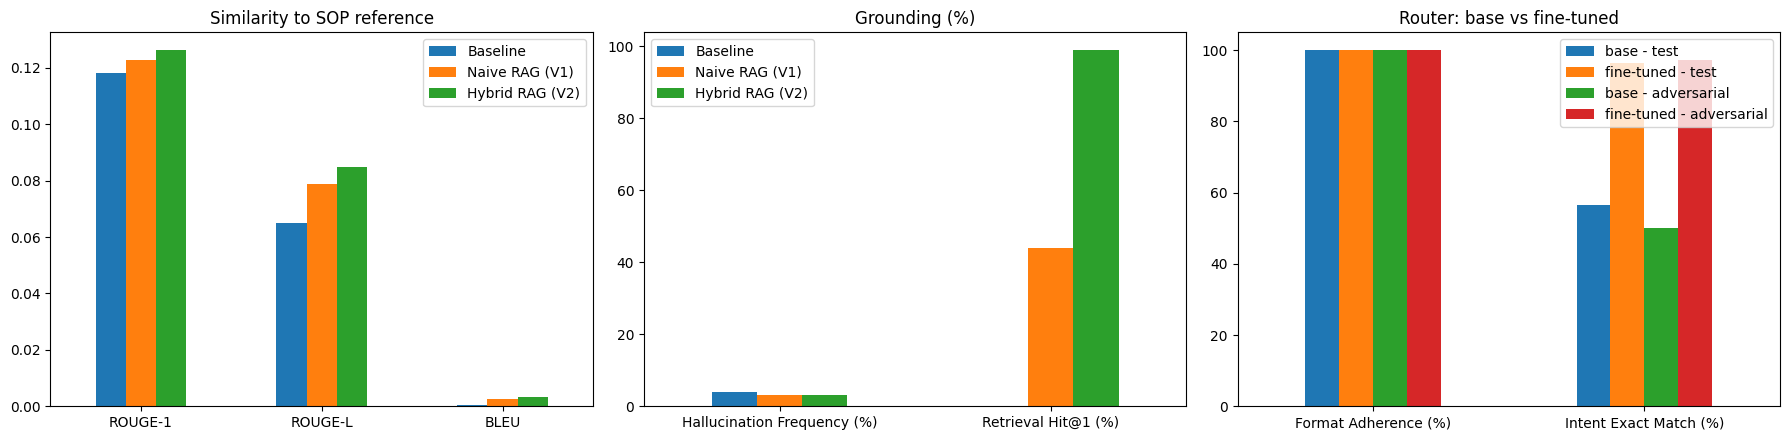

In [6]:
def system_scores(name, hit=np.nan, router_fmt=np.nan, acc=np.nan, acc_adv=np.nan):
    return {'Router Format Adherence (%)': router_fmt,
            'Intent Accuracy - test (%)': acc,
            'Intent Accuracy - adversarial (%)': acc_adv,
            'Retrieval Hit@1 (%)': hit,
            'Response Format Adherence (%)': full[f'{name}_format_ok'].mean() * 100,
            'ROUGE-1': full[f'{name}_rouge1'].mean(),
            'ROUGE-L': full[f'{name}_rougeL'].mean(),
            'BLEU': full[f'{name}_bleu'].mean(),
            'Consistency Rate (%)': consistency[name],
            'Hallucination Frequency (%)': full[f'{name}_hallucinated'].mean() * 100}

ft = router_table['fine-tuned - test']
summary = pd.DataFrame({
    'Baseline': system_scores('baseline'),
    'Naive RAG (V1)': system_scores('naive', full.naive_retrieval_hit.mean() * 100),
    'Hybrid RAG (V2)': system_scores('hybrid', full.hybrid_retrieval_hit.mean() * 100, ft['Format Adherence (%)'],
                                     ft['Intent Exact Match (%)'], router_table.loc['Intent Exact Match (%)', 'fine-tuned - adversarial']),
})
summary['V1 vs Baseline (%)'] = [pct_change(a, b) for a, b in zip(summary['Naive RAG (V1)'], summary['Baseline'])]
summary['V2 vs V1 (%)'] = [pct_change(a, b) for a, b in zip(summary['Hybrid RAG (V2)'], summary['Naive RAG (V1)'])]
summary['V2 vs Baseline (%)'] = [pct_change(a, b) for a, b in zip(summary['Hybrid RAG (V2)'], summary['Baseline'])]
display(summary.round(4))

keep = ['text', 'intent', 'category', 'adversarial', 'reference_sop',
        'baseline_output', 'baseline_format_ok', 'baseline_rouge1', 'baseline_rougeL', 'baseline_bleu', 'baseline_hallucinated',
        'naive_retrieved_sop', 'naive_retrieval_hit', 'naive_rag_output', 'naive_format_ok', 'naive_rouge1', 'naive_rougeL',
        'naive_bleu', 'naive_hallucinated',
        'router_raw', 'strict_json', 'pred_intent', 'pred_category', 'routed', 'hybrid_retrieved_sop',
        'hybrid_retrieval_hit', 'hybrid_output', 'hybrid_format_ok', 'hybrid_rouge1', 'hybrid_rougeL', 'hybrid_bleu',
        'hybrid_hallucinated']
full[keep].to_csv('Comparative_Results_Full.csv', index=False)
summary.to_csv('Comparative_Results_Summary.csv')
router_table.to_csv('router_metrics.csv')

systems = ['Baseline', 'Naive RAG (V1)', 'Hybrid RAG (V2)']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
summary.loc[['ROUGE-1', 'ROUGE-L', 'BLEU'], systems].plot.bar(ax=axes[0], rot=0, title='Similarity to SOP reference')
summary.loc[['Hallucination Frequency (%)', 'Retrieval Hit@1 (%)'], systems].plot.bar(ax=axes[1], rot=0, title='Grounding (%)')
router_table.loc[['Format Adherence (%)', 'Intent Exact Match (%)']].plot.bar(ax=axes[2], rot=0, title='Router: base vs fine-tuned')
plt.tight_layout()
plt.savefig('comparative_metrics.png', dpi=120)
plt.show()

outputs['hybrid_rag_output'] = demo.hybrid_output
outputs['hybrid_router_output'] = demo.router_raw
outputs['hybrid_retrieved_sop'] = demo.hybrid_retrieved_sop
with open('outputs.json', 'w') as f:
    json.dump(outputs, f, indent=2)

---
## END-OF-NOTEBOOK CHECKLIST (FINAL)

> **IMPORTANT: This is the last graded notebook. Verify all deliverables.**

- [ ] **4.3.1** LoRA merged + Hybrid RAG integration validated (intent → search → retrieve → generate)
- [ ] **4.4.1** Format Adherence + Exact Match + Fuzzy Match on test split + adversarial subset
- [ ] **4.4.2** Fine-tuning impact quantified (V1 vs V2 with %)
- [ ] **4.5** All 3 architectures scored with SOP-grounded references
- [ ] **`Comparative_Results_Full.csv` saved** ← _FINAL DELIVERABLE_
- [ ] **`Comparative_Results_Summary.csv` saved** ← _FINAL DELIVERABLE_

### Complete Artifact Inventory

| Artifact | Created In |
|---|---|
| `sampled_data.csv` | NB1 |
| `./tokenized_train/`, `./tokenized_valid/`, `df_test.csv` | NB2 |
| `outputs.json` | NB3 + NB4 |
| `./chroma_db/` | NB4 |
| `v1_metrics.csv` | NB5 |
| `./intent_lora_best/`, `training_log.csv`, `training_curves.png` | NB6 |
| `Comparative_Results_Full.csv`, `Comparative_Results_Summary.csv` | NB7 |

**Mark all items checked, then prepare your final submission package.**